In [51]:
import torch
import numpy as np
from matplotlib import pyplot as plt

import sys
sys.path.append("../")
#
import torch.nn as nn

from time import time

import re

from sklearn.decomposition import NMF

from nltk.corpus import stopwords
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer

import ssnmf
from ssnmf import SSNMF

import pandas as pd

In [52]:
#"documents" are the individual tweets
tweets = pd.read_csv('../data cleaning/text of tweets.csv',names=["tweet_id","tweet"]) 
documents=tweets["tweet"]

#vectorizer=TfidfVectorizer(stop_words='english')
#stopwords_list+= ["rt", "https://t.co/pIPCd6Nu9s","https://t.co/DdGBGsLBKe","pipcd6nu9s", "ddgbgslbke", "https"]

#Possible experiment: more or fewer stopwords removed.
stopwords_list=stopwords.words("english")
stopwords_list+= ["rt", "RT"]

#additional cleaning for web addresses
def cleaner(s):
    out=re.sub(r'http.*\s?', '',s)
    out=re.sub(r'\s\d+','',out)
    out=re.sub(r':\d+','',out)
    out= out.lower()
    return out
#vectorizer=TfidfVectorizer(stop_words=stopwords_list, preprocessor=lambda s: re.sub(r'http.*\s?', '',s).lower())
vectorizer=TfidfVectorizer(stop_words=stopwords_list,preprocessor=cleaner)

vectors = vectorizer.fit_transform(documents)

idx_to_word = np.array(vectorizer.get_feature_names_out())

np.save("../NMF/all_tweets.npy", vectors)
np.save("../NMF/all_tweets_words.npy", idx_to_word)

In [53]:


def d_to_v(d, verbose=True):
    """
    Given dictionary d of form {word: weight}, created GT topic vector v. See writeup for details.
    """
    l = list(idx_to_word)
    v = np.zeros(idx_to_word.shape[0])
    
    for key in d.keys():
        i = l.index(key)
        if(i < 0):
            print("Could not find word '" + key + "' in list of words!")
        else:
            v[i] = d[key]
            
    return v



In [54]:
X = np.load("../NMF/all_tweets.npy", allow_pickle=True)
print(X)
idx_to_word = np.load("../NMF/all_tweets_words.npy", allow_pickle=True)

X = X.item().T

X_avg = X.toarray()

groupNum = 7

  (0, 1443)	1.0
  (1, 74)	0.20844862429775834
  (1, 534)	0.24431134706176078
  (1, 831)	0.18592542213814817
  (1, 844)	0.25177821397028716
  (1, 835)	0.24788904015679325
  (1, 756)	0.21508259812135863
  (1, 1428)	0.25177821397028716
  (1, 770)	0.11163008140589134
  (1, 1250)	0.20133886157007605
  (1, 976)	0.287020130890539
  (1, 827)	0.2719807296431492
  (1, 1087)	0.287020130890539
  (1, 591)	0.2560383218812165
  (1, 654)	0.21164264720687612
  (1, 401)	0.05995062342451459
  (1, 161)	0.30985265817543833
  (1, 1425)	0.12538088528301924
  (1, 1407)	0.2719807296431492
  (1, 1472)	0.19084216539552062
  (2, 770)	0.1027214958811364
  (2, 401)	0.05516629245105819
  (2, 1456)	0.16940871324571058
  (2, 1227)	0.20920569125311278
  (2, 1338)	0.22176611645774041
  :	:
  (1127, 1695)	0.415567804125753
  (1127, 1457)	0.4086533560194068
  (1127, 1593)	0.3911578216441329
  (1128, 1647)	0.1801416958298823
  (1128, 157)	0.2890667358961672
  (1128, 790)	0.29856972266188836
  (1128, 1336)	0.262441419462930

In [55]:
np.random.seed(1)

model = SSNMF(X_avg.T,groupNum)

W0 = model.A
H0 = model.S

N = 200
model.mult(numiters=N)

W = model.A.T
H = model.S.T

print(W)
print(H)



[[0.00000000e+00 1.32212417e-03 2.09014210e-03 ... 8.32140827e-04
  2.71442611e-04 5.22543119e-04]
 [0.00000000e+00 8.27359039e-07 4.16763466e-08 ... 5.68213232e-06
  6.65676849e-62 1.34975149e-07]
 [0.00000000e+00 5.60113789e-05 2.24396655e-06 ... 2.32124007e-08
  2.87995139e-09 2.84971622e-05]
 ...
 [0.00000000e+00 1.22096148e-09 3.22277508e-04 ... 1.78925894e-09
  5.34785873e-14 7.34325706e-07]
 [0.00000000e+00 2.51573643e-09 2.12869928e-08 ... 3.80905047e-04
  6.23358215e-10 1.03087150e-11]
 [0.00000000e+00 1.77873294e-04 5.72704943e-19 ... 5.54768027e-33
  2.39745431e-23 1.48109618e-08]]
[[1.95869749e-006 2.40738603e+000 3.26063323e-017 ... 9.89843681e-027
  9.64946821e-001 7.17902005e-038]
 [1.31837003e-001 2.23001514e-038 1.75072815e+000 ... 3.14408777e-033
  3.26225317e-002 2.41877842e-001]
 [3.76117445e-001 2.34719041e-025 4.83042425e-009 ... 5.86364733e-037
  2.04477487e-010 3.34272649e-002]
 ...
 [4.70813638e-002 9.64754752e-015 2.26562364e-020 ... 2.04530743e-043
  3.671835

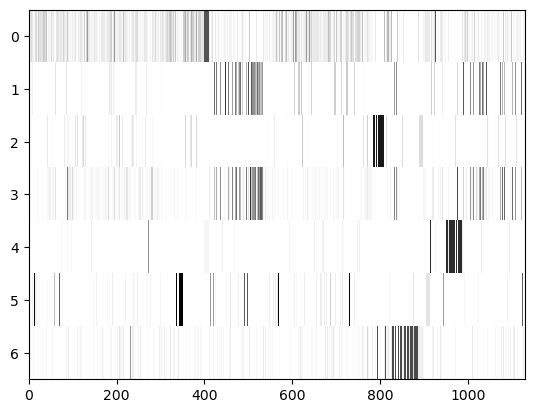

Topic 1     Topic 2          Topic 3       Topic 4      Topic 5   Topic 6     Topic 7  
-------     -------          -------       -------      -------   -------     -------  
jmm2020     user172          fundamental   user172      deadline  non         erica    
user36      disruptjmm       question      disruptjmm   pcmi      binary      graham   
disruptjmm  starts           asking        disruptmath  programs  panel       anti     
hope        land             things        jmm          heels     trans       di       
consider    people           two           ones         extended  students    user197  
honor       explanation      mathematical  much         several   supporting  dr       
challenge   acknowledgments  user78        statement    user112   saturday    racism   

For LaTeX table...
------------------
jmm2020 & user172 & fundamental & user172 \\
user36 & disruptjmm & question & disruptjmm \\
disruptjmm & starts & asking & disruptmath \\
hope & land & things & jmm \\
c

In [56]:
top_to_show = 7

plt.imshow(W,aspect='auto',cmap='binary',interpolation='none')
plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(H.shape[1]):
    col = H[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 


col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")

Create Seed topics (Y matrix)

In [57]:
seed1 = {"trans": 1}
seed2 = {"question": 1}

gt_topic_words= [seed1, seed2]
gt_topic_vectors= [d_to_v(x) for x in gt_topic_words]

Y = np.stack(gt_topic_vectors).T


In [58]:
np.random.seed(1)

model_2 = SSNMF(X_avg.T,groupNum,Y=Y.T,lam=0.5)
N=200
model_2.mult(numiters = N)

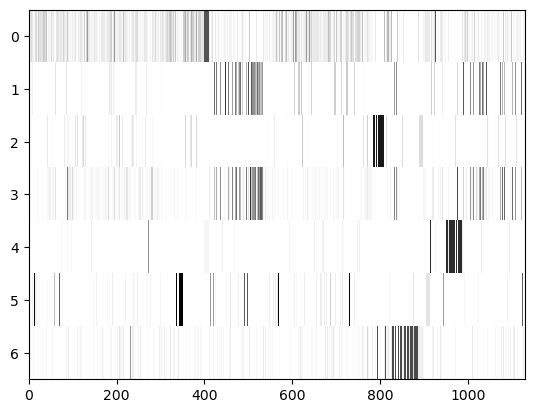

Topic 1     Topic 2          Topic 3       Topic 4      Topic 5   Topic 6     Topic 7  
-------     -------          -------       -------      -------   -------     -------  
jmm2020     user172          fundamental   user172      deadline  non         erica    
user36      disruptjmm       question      disruptjmm   pcmi      binary      graham   
disruptjmm  starts           asking        disruptmath  programs  panel       anti     
hope        land             things        jmm          heels     trans       di       
consider    people           two           ones         extended  students    user197  
honor       explanation      mathematical  much         several   supporting  dr       
challenge   acknowledgments  user78        statement    user112   saturday    racism   

For LaTeX table...
------------------
jmm2020 & user172 & fundamental & user172 \\
user36 & disruptjmm & question & disruptjmm \\
disruptjmm & starts & asking & disruptmath \\
hope & land & things & jmm \\
c

In [59]:
S = model_2.A.T
A = model_2.S.T

plt.imshow(S,aspect='auto',cmap='binary',interpolation='none')
plt.show()

keywords = np.empty((top_to_show+2,groupNum), dtype=object)

for i in range(keywords.shape[1]):
    keywords[0,i] = "Topic " + str(i+1)
    keywords[1,i] = "-------"

for i in range(A.shape[1]):
    col = A[:,i]
    top = col.argsort()
    top = top[-1*top_to_show:][::-1]

    keywords[2:,i] = idx_to_word[top] 

col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for row in keywords:
    print("".join(row[i].ljust(col_widths[i]) for i in range(len(row))))
    
print("")
print("For LaTeX table...")  
print("------------------")
col_widths = [max([len(keywords[i][j]) for i in range(keywords.shape[0])])+2 for j in range(keywords.shape[1])]
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(0,4)]) + " \\\\")
for i, row in enumerate(keywords):
    if(i >= 2):
        print(" & ".join([row[i] for i in range(4,min(8,groupNum))]) + " \\\\")